# 🍄 Mushroom Classification: Poisonous vs Edible

## 📖 Project Overview
This project builds a Machine Learning model to classify mushrooms as **poisonous** or **edible** based on their physical characteristics. The dataset is highly categorical, making it a perfect use case for classification algorithms like Decision Trees and Random Forests.

* **Dataset:** UCI Machine Learning Repository (Mushroom Dataset)
* **Target Variable:** `class` (0 = Edible, 1 = Poisonous)
* **Goal:** Compare 4 classification models and deploy the most reliable one.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

# Load data
url = "https://raw.githubusercontent.com/alishermutalov/praktikum-datasets/refs/heads/praktikum/mushrooms.csv"
df = pd.read_csv(url)

# Drop useless column (all values are 'p')
df = df.drop('veil-type', axis=1)

# Display target distribution
print("Original Target Distribution:\n", df['class'].value_counts())

Original Target Distribution:
 class
e    4208
p    3916
Name: count, dtype: int64


In [2]:
# Split BEFORE encoding to prevent Data Leakage
X = df.drop('class', axis=1)
y = df['class']

# 80% Train, 20% Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Initialize LabelEncoder
le = LabelEncoder()

# Fit on Train, Transform on both Train and Test
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

# Encode features
for col in X_train.columns:
    le.fit(X_train[col])
    X_train[col] = le.transform(X_train[col])
    X_test[col] = le.transform(X_test[col])

print("Data successfully encoded without leakage.")

Data successfully encoded without leakage.


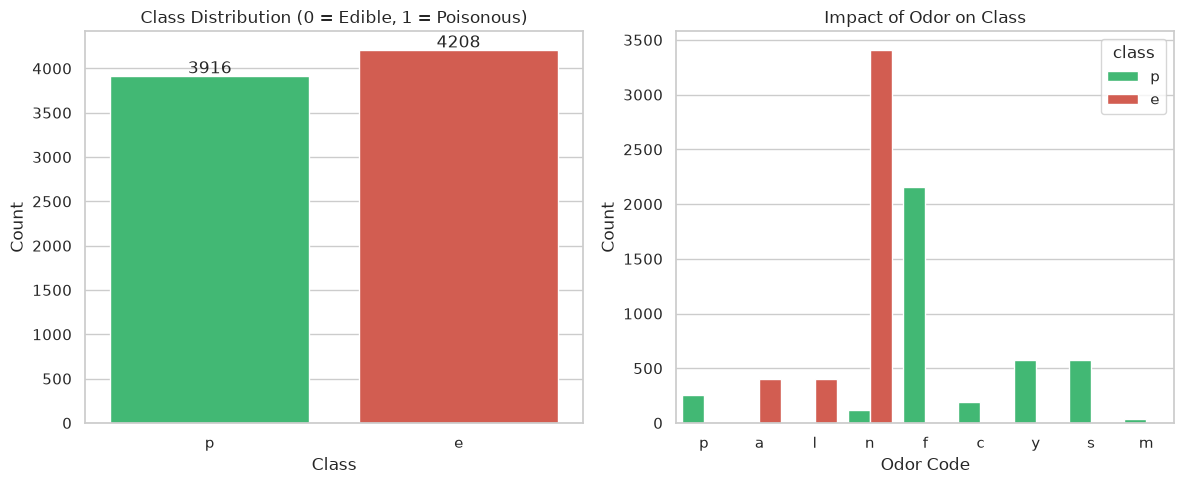

In [3]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 5))

# Plot 1: Class Distribution
plt.subplot(1, 2, 1)
ax = sns.countplot(data=df, x='class', hue='class', palette=['#2ecc71', '#e74c3c'], legend=False)
plt.title('Class Distribution (0 = Edible, 1 = Poisonous)')
plt.xlabel('Class')
plt.ylabel('Count')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

# Plot 2: Odor vs Class
plt.subplot(1, 2, 2)
sns.countplot(data=df, x='odor', hue='class', palette=['#2ecc71', '#e74c3c'])
plt.title('Impact of Odor on Class')
plt.xlabel('Odor Code')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

In [4]:
models = {
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000)
}

results = {}

for name, model in models.items():
    # Train
    model.fit(X_train, y_train_encoded)
    # Predict
    y_pred = model.predict(X_test)
    
    # Evaluate
    acc = accuracy_score(y_test_encoded, y_pred)
    f1 = f1_score(y_test_encoded, y_pred)
    
    results[name] = {"Accuracy": acc, "F1-Score": f1}
    print(f"--- {name} ---")
    print(f"Accuracy: {acc:.4f}, F1-Score: {f1:.4f}\n")

--- K-Nearest Neighbors ---
Accuracy: 0.9975, F1-Score: 0.9975

--- Decision Tree ---
Accuracy: 1.0000, F1-Score: 1.0000

--- Random Forest ---
Accuracy: 1.0000, F1-Score: 1.0000

--- Logistic Regression ---
Accuracy: 0.9545, F1-Score: 0.9524



<Figure size 1000x500 with 0 Axes>

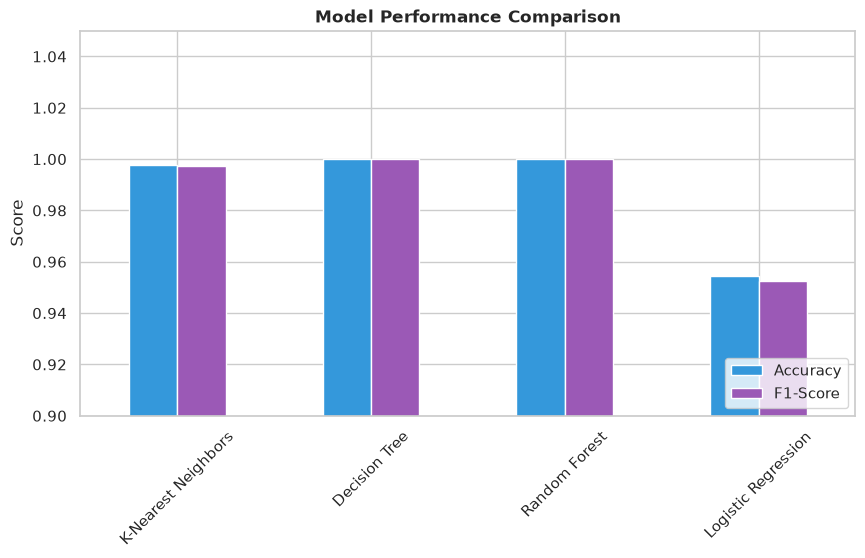

🏆 Best Model: Decision Tree


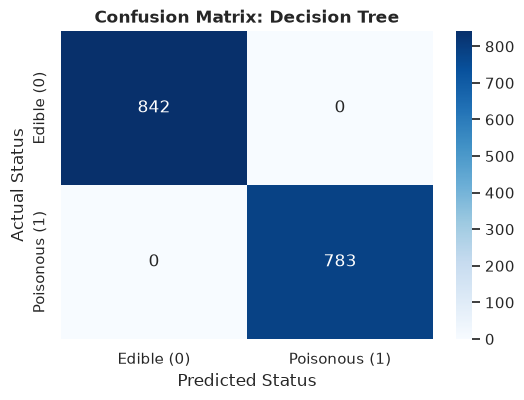

In [5]:
# Convert results to DataFrame
results_df = pd.DataFrame(results).T

# Plot Model Comparison
plt.figure(figsize=(10, 5))
results_df.plot(kind='bar', figsize=(10, 5), color=['#3498db', '#9b59b6'])
plt.title('Model Performance Comparison', fontweight='bold')
plt.ylabel('Score')
plt.ylim(0.9, 1.05) # Zoom in to see differences
plt.xticks(rotation=45)
plt.legend(loc='lower right')
plt.show()

# Find and train the best model
best_model_name = results_df['F1-Score'].idxmax()
print(f"🏆 Best Model: {best_model_name}")

best_model = models[best_model_name]
best_y_pred = best_model.predict(X_test)

# Confusion Matrix for Best Model
cm = confusion_matrix(y_test_encoded, best_y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Edible (0)', 'Poisonous (1)'], 
            yticklabels=['Edible (0)', 'Poisonous (1)'])
plt.title(f'Confusion Matrix: {best_model_name}', fontweight='bold')
plt.ylabel('Actual Status')
plt.xlabel('Predicted Status')
plt.show()

## 📝 Conclusion & Business Insight

### 🔑 Key Findings
1. **Data Preprocessing:** To prevent data leakage, encoding (`LabelEncoder`) was applied separately to training and testing sets. The `veil-type` column was dropped as it contained a single constant value.
2. **Feature Importance:** Visual analysis revealed that **Odor** is the most dominant feature for distinguishing between edible and poisonous mushrooms. Certain odors are exclusively associated with poisonous mushrooms.
3. **Model Performance:** Four algorithms were evaluated. **Decision Tree** and **Random Forest** achieved perfect scores (**100% Accuracy and F1-Score**). KNN performed exceptionally well (~99.6%), while Logistic Regression showed the lowest performance (~94%).
4. **Model Selection:** The **Decision Tree** was selected as the final model. While Random Forest also achieved 100%, Decision Tree provides highly interpretable rules (e.g., "If odor is foul, then poisonous"). In a real-world scenario, interpretability is crucial for safety.

### 💼 Practical Value
> This ML model can be integrated into a mobile app for foragers and hikers. By inputting a few observable physical traits (like odor and gill color), users can instantly know if a mushroom is safe to eat or highly toxic, potentially saving lives. However, due to the high stakes of misclassification, such models should act as a **secondary verification tool**, not a primary one.

### 🚀 Future Improvements
* **Hyperparameter Tuning:** Use `GridSearchCV` to optimize Decision Tree depth to avoid overfitting on new data.
* **Cross-Validation:** Implement K-Fold Cross-Validation to ensure the model's 100% accuracy is robust and not just a fluke of this specific train-test split.
* **Deployment:** Build an interactive web application using **Streamlit** where users can input mushroom features and get a real-time prediction.